# Warehouse Inventory & Stockout Risk Analysis
**Mini Project | B.Tech 1st Year**
**Student:** Krishna Goyal
**Admission No.:** 2026b01010173
**Github repo:**https://github.com/krishnagoyal9900-png/Krishna.git
**Tools used:** Python, NumPy, pandas (and matplotlib for charts)

---

## What is the problem?
A warehouse stores many products. If a product **runs out of stock** (a *stockout*), the business loses sales and customers get unhappy. If we keep **too much stock**, money gets blocked in unsold goods.

In this project we analyse the sales and stock of **20 warehouse products** and answer four questions:

1. How fast does each product sell? (average daily demand)
2. When should we place a new order? (reorder point and safety stock)
3. Which products are at **risk of stockout**? (risk level for every product)
4. Which products matter most to the business? (ABC analysis)



## Step 1: Import the libraries
- **NumPy** is used for fast number work (random numbers, arrays, maths).
- **pandas** is used for tables (DataFrames), grouping and summaries.
- **matplotlib** is used to draw charts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)   # show all columns
pd.set_option("display.width", 150)

np.random.seed(42)   # fixed seed -> same random numbers every time you run

print("Libraries loaded.  pandas", pd.__version__, "| numpy", np.__version__)

Libraries loaded.  pandas 2.2.3 | numpy 2.4.6


## Step 2: Create the product list (product master data)
Every product has an ID, name, category, cost price (in Rs), supplier **lead time** (days the supplier takes to deliver after we order) and the **current stock** in the warehouse today.

> In a real project this table would come from a file, e.g. `pd.read_csv("products.csv")`. Here we type it in so the notebook runs anywhere.

In [2]:
products = pd.DataFrame({
    "product_id": ["P01", "P02", "P03", "P04", "P05", "P06", "P07", "P08", "P09", "P10",
                   "P11", "P12", "P13", "P14", "P15", "P16", "P17", "P18", "P19", "P20"],
    "product_name": ["USB Cable", "Wireless Mouse", "Earphones", "Power Bank", "Phone Charger",
                     "Basmati Rice 5kg", "Cooking Oil 1L", "Tea Powder 500g", "Sugar 1kg", "Wheat Flour 5kg",
                     "Detergent 1kg", "Dish Soap", "LED Bulb 9W", "Floor Cleaner", "Bath Soap Pack",
                     "Notebook A4", "Ball Pen Pack", "Marker Set", "Stapler", "Sticky Notes"],
    "category": ["Electronics"] * 5 + ["Groceries"] * 5 + ["Household"] * 5 + ["Stationery"] * 5,
    "unit_cost":      [120, 450, 300, 900, 350,  420, 160, 230, 45, 230,  110, 60, 80, 120, 150,  40, 50, 90, 70, 35],
    "lead_time_days": [  7,  10,   8,  12,   7,    4,   3,   5,  3,   4,    5,  4,  6,   5,   4,   6,  5,  7,  8,  5],
    "current_stock":  [ 90, 150,  85,  40, 120,   70,  45,  80, 95,  60,  100, 65, 200, 50,  95, 400, 130, 30, 60, 58],
})

products.head()

,product_id,product_name,category,unit_cost,lead_time_days,current_stock
0,P01,USB Cable,Electronics,120,7,90
1,P02,Wireless Mouse,Electronics,450,10,150
2,P03,Earphones,Electronics,300,8,85
3,P04,Power Bank,Electronics,900,12,40
4,P05,Phone Charger,Electronics,350,7,120


## Step 3: Create 120 days of daily sales data
We make **sample sales data** using NumPy:
- Each product has a *typical daily demand* (`base_demand`).
- Weekends sell **30% more** than weekdays.
- Real sales are never exactly the same every day, so we use `np.random.poisson()`, which creates realistic random "counts" (like number of units sold per day).

We store the result in a table where **rows = dates** and **columns = products**.

In [3]:
days = 120
dates = pd.date_range(end="2026-11-19", periods=days)   # last 120 days

# typical units sold per day for P01 ... P20
base_demand = np.array([14, 6, 9, 4, 8,   12, 18, 10, 25, 15,   11, 13, 16, 7, 20,   30, 22, 5, 3, 9])

# weekend factor: Saturday = 5, Sunday = 6
is_weekend = dates.dayofweek >= 5
day_factor = np.where(is_weekend, 1.3, 1.0)

# NumPy broadcasting: (120 x 1) * (1 x 20) -> (120 x 20) table of expected demand
expected = day_factor.reshape(-1, 1) * base_demand.reshape(1, -1)

# random daily sales around the expected demand
sales_array = np.random.poisson(expected)

sales = pd.DataFrame(sales_array, index=dates, columns=products["product_id"])
sales.index.name = "date"

print("Shape of sales table (days x products):", sales.shape)
sales.head()

Shape of sales table (days x products): (120, 20)


product_id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20
date,,,,,,,,,,,,,,,,,,,,
2026-07-23,17,2,8,4,7,8,22,5,24,15,16,15,16,9,18,26,20,3,3,10
2026-07-24,12,10,3,5,7,12,24,5,24,20,11,10,14,9,20,25,18,7,3,6
2026-07-25,21,9,12,6,13,9,31,15,26,22,11,13,24,12,27,33,25,6,8,8
2026-07-26,26,10,9,11,5,16,25,11,33,15,8,17,23,7,29,32,24,9,1,7
2026-07-27,16,4,9,2,12,7,11,4,31,19,12,10,14,10,27,21,23,7,1,8


## Step 4: Check the data quality
Before any analysis we check for **missing values** and **wrong values** (like negative sales).

In [4]:
print("Missing values      :", sales.isna().sum().sum())
print("Negative values     :", (sales < 0).sum().sum())
print("Total units sold    :", sales.values.sum())
print("Date range          :", sales.index.min().date(), "to", sales.index.max().date())

# quick statistics for the first 5 products
sales.iloc[:, :5].describe().round(1)

Missing values      : 0
Negative values     : 0
Total units sold    : 33293
Date range          : 2026-07-23 to 2026-11-19


product_id,P01,P02,P03,P04,P05
count,120.0,120.0,120.0,120.0,120.0
mean,14.7,6.4,10.1,4.3,8.2
std,4.1,2.7,3.1,2.3,3.2
min,6.0,1.0,2.0,0.0,2.0
25%,12.0,4.0,8.0,3.0,6.0
50%,15.0,6.0,10.0,4.0,8.0
75%,18.0,8.0,12.0,6.0,10.0
max,26.0,13.0,17.0,11.0,19.0


## Step 5: Find the demand of every product
For each product we calculate:
- **Average daily demand** - how many units sell per day on average
- **Standard deviation** - how much daily sales vary (more variation = more risk)
- **Maximum daily demand** and **total units sold**

Then we join (`merge`) this with the product list to make one main table called `inventory`.

In [5]:
demand_stats = pd.DataFrame({
    "avg_daily_demand": sales.mean(),
    "std_daily_demand": sales.std(),
    "max_daily_demand": sales.max(),
    "total_units_sold": sales.sum(),
}).round(2)

demand_stats = demand_stats.reset_index()          # product_id becomes a normal column

inventory = products.merge(demand_stats, on="product_id")
inventory[["product_id", "product_name", "avg_daily_demand", "std_daily_demand",
           "max_daily_demand", "total_units_sold"]]

,product_id,product_name,avg_daily_demand,std_daily_demand,max_daily_demand,total_units_sold
0,P01,USB Cable,14.72,4.09,26,1766
1,P02,Wireless Mouse,6.41,2.70,13,769
2,P03,Earphones,10.10,3.09,17,1212
3,P04,Power Bank,4.29,2.34,11,515
4,P05,Phone Charger,8.23,3.18,19,988
5,P06,Basmati Rice 5kg,12.86,3.77,22,1543
6,P07,Cooking Oil 1L,19.65,5.69,38,2358
7,P08,Tea Powder 500g,10.32,3.36,19,1239
8,P09,Sugar 1kg,27.53,6.01,42,3304
9,P10,Wheat Flour 5kg,15.98,4.46,27,1918


## Step 6: Calculate inventory measures
| Measure | Meaning | Formula used |
|---|---|---|
| **Stock value** | Money locked in current stock | `stock x unit cost` |
| **Days of stock left** | For how many days current stock will last | `stock / average daily demand` |
| **Safety stock** | Extra stock kept for sudden demand | `1.65 x std x sqrt(lead time)` |
| **Reorder point (ROP)** | When stock falls to this level, place a new order | `avg demand x lead time + safety stock` |

The number **1.65** is the standard value for a **95% service level** (we want to avoid stockouts 95% of the time).

In [6]:
Z = 1.65   # z-value for 95% service level

inventory["stock_value"] = inventory["current_stock"] * inventory["unit_cost"]
inventory["days_of_stock_left"] = (inventory["current_stock"] / inventory["avg_daily_demand"]).round(1)

inventory["safety_stock"] = np.ceil(Z * inventory["std_daily_demand"] * np.sqrt(inventory["lead_time_days"]))
inventory["reorder_point"] = np.ceil(inventory["avg_daily_demand"] * inventory["lead_time_days"]
                                     + inventory["safety_stock"])

# is the current stock already at or below the reorder point?
inventory["reorder_now"] = np.where(inventory["current_stock"] <= inventory["reorder_point"], "Yes", "No")

inventory[["product_name", "current_stock", "lead_time_days", "days_of_stock_left",
           "safety_stock", "reorder_point", "reorder_now"]]

,product_name,current_stock,lead_time_days,days_of_stock_left,safety_stock,reorder_point,reorder_now
0,USB Cable,90,7,6.1,18.0,122.0,Yes
1,Wireless Mouse,150,10,23.4,15.0,80.0,No
2,Earphones,85,8,8.4,15.0,96.0,Yes
3,Power Bank,40,12,9.3,14.0,66.0,Yes
4,Phone Charger,120,7,14.6,14.0,72.0,No
5,Basmati Rice 5kg,70,4,5.4,13.0,65.0,No
6,Cooking Oil 1L,45,3,2.3,17.0,76.0,Yes
7,Tea Powder 500g,80,5,7.8,13.0,65.0,No
8,Sugar 1kg,95,3,3.5,18.0,101.0,Yes
9,Wheat Flour 5kg,60,4,3.8,15.0,79.0,Yes


## Step 7: Stockout probability using simulation (Monte Carlo)
**Question:** If we order *today*, the new stock arrives after the lead time. What is the chance that customers buy **more** than our current stock during that waiting time?

**Idea:** we simulate the lead time **10,000 times** using random daily demand. Then we count in how many simulations the demand was larger than the stock.

`stockout probability = (simulations where demand > stock) / 10,000`

In [7]:
SIMULATIONS = 10000
stockout_prob = []

for i in range(len(inventory)):
    row = inventory.iloc[i]
    lead = int(row["lead_time_days"])

    # 10,000 simulated lead periods, each with 'lead' days of random demand
    daily_demand = np.random.poisson(row["avg_daily_demand"], size=(SIMULATIONS, lead))
    demand_in_lead_time = daily_demand.sum(axis=1)        # total demand in each simulation

    prob = (demand_in_lead_time > row["current_stock"]).mean()   # share of simulations with stockout
    stockout_prob.append(prob)

inventory["stockout_prob_pct"] = np.round(np.array(stockout_prob) * 100, 1)

inventory[["product_name", "current_stock", "stockout_prob_pct"]].sort_values("stockout_prob_pct", ascending=False)

,product_name,current_stock,stockout_prob_pct
6,Cooking Oil 1L,45,96.5
3,Power Bank,40,93.8
0,USB Cable,90,89.1
17,Marker Set,30,83.7
9,Wheat Flour 5kg,60,66.6
2,Earphones,85,28.9
14,Bath Soap Pack,95,13.6
16,Ball Pen Pack,130,13.3
11,Dish Soap,65,11.7
8,Sugar 1kg,95,8.2


## Step 8: Give every product a risk level
We convert the stockout probability into a simple label:

| Stockout probability | Risk level |
|---|---|
| 50% or more | **Critical** |
| 20% to 50% | **High** |
| 5% to 20% | **Medium** |
| below 5% | **Low** |

In [8]:
def get_risk_level(p):
    if p >= 50:
        return "Critical"
    elif p >= 20:
        return "High"
    elif p >= 5:
        return "Medium"
    else:
        return "Low"

risk_order = ["Critical", "High", "Medium", "Low"]
inventory["risk_level"] = inventory["stockout_prob_pct"].apply(get_risk_level)
inventory["risk_level"] = pd.Categorical(inventory["risk_level"], categories=risk_order, ordered=True)

print("Number of products in each risk level:")
inventory["risk_level"].value_counts().sort_index()

Number of products in each risk level:


,count
risk_level,
Critical,5
High,1
Medium,5
Low,9


## Step 9: How much should we order?
For every product that has reached its reorder point, we suggest an order that brings stock up to:

`target stock = reorder point + 14 days of average demand`

Products that are not at the reorder point get an order quantity of 0.

In [9]:
target_stock = inventory["reorder_point"] + inventory["avg_daily_demand"] * 14

order_qty = np.where(inventory["reorder_now"] == "Yes",
                     np.ceil(target_stock - inventory["current_stock"]),
                     0)

inventory["suggested_order_qty"] = order_qty.astype(int)
inventory["order_cost"] = inventory["suggested_order_qty"] * inventory["unit_cost"]

orders = inventory[inventory["suggested_order_qty"] > 0]
orders = orders.sort_values("risk_level")[["product_name", "risk_level", "current_stock", "reorder_point",
                                           "suggested_order_qty", "order_cost"]]
print("Products to reorder:", len(orders))
print("Total purchase budget needed: Rs", int(orders["order_cost"].sum()))
orders

Products to reorder: 11
Total purchase budget needed: Rs 364025


,product_name,risk_level,current_stock,reorder_point,suggested_order_qty,order_cost
0,USB Cable,Critical,90,122.0,239,28680
3,Power Bank,Critical,40,66.0,87,78300
6,Cooking Oil 1L,Critical,45,76.0,307,49120
9,Wheat Flour 5kg,Critical,60,79.0,243,55890
17,Marker Set,Critical,30,47.0,90,8100
2,Earphones,High,85,96.0,153,45900
8,Sugar 1kg,Medium,95,101.0,392,17640
11,Dish Soap,Medium,65,70.0,203,12180
14,Bath Soap Pack,Medium,95,105.0,309,46350
16,Ball Pen Pack,Medium,130,138.0,340,17000


## Step 10: Category-wise summary (pandas `groupby`)
Now we look at the warehouse **category by category**.

In [10]:
category_summary = inventory.groupby("category").agg(
    products=("product_id", "count"),
    units_sold=("total_units_sold", "sum"),
    stock_value=("stock_value", "sum"),
    avg_stockout_risk_pct=("stockout_prob_pct", "mean"),
).round(1)

category_summary

,products,units_sold,stock_value,avg_stockout_risk_pct
category,,,,
Electronics,5,5250,181800,42.4
Groceries,5,10362,73075,34.4
Household,5,8733,51150,5.3
Stationery,5,8948,31430,20.9


In [11]:
# how many products of each risk level are there in every category?
pd.crosstab(inventory["category"], inventory["risk_level"])

risk_level,Critical,High,Medium,Low
category,,,,
Electronics,2,1,0,2
Groceries,2,0,1,2
Household,0,0,2,3
Stationery,1,0,2,2


## Step 11: ABC analysis (which products matter most?)
We rank products by **sales value** (`units sold x unit cost`) and calculate the running (cumulative) percentage:

- **Class A** - products that make the first 70% of sales value (most important)
- **Class B** - products that make the next 20%
- **Class C** - the remaining 10% (least important)

In [12]:
inventory["sales_value"] = inventory["total_units_sold"] * inventory["unit_cost"]

abc = inventory.sort_values("sales_value", ascending=False)[["product_id", "product_name", "sales_value"]].copy()
abc["share_pct"] = (abc["sales_value"] / abc["sales_value"].sum() * 100).round(1)
abc["cumulative_pct"] = (abc["sales_value"].cumsum() / abc["sales_value"].sum() * 100).round(1)
abc["abc_class"] = np.where(abc["cumulative_pct"] <= 70, "A",
                    np.where(abc["cumulative_pct"] <= 90, "B", "C"))

# add the class back to the main table
inventory = inventory.merge(abc[["product_id", "abc_class"]], on="product_id")

abc.reset_index(drop=True)

,product_id,product_name,sales_value,share_pct,cumulative_pct,abc_class
0,P06,Basmati Rice 5kg,648060,13.0,13.0,A
1,P04,Power Bank,463500,9.3,22.3,A
2,P10,Wheat Flour 5kg,441140,8.9,31.2,A
3,P15,Bath Soap Pack,383700,7.7,38.9,A
4,P07,Cooking Oil 1L,377280,7.6,46.5,A
5,P03,Earphones,363600,7.3,53.8,A
6,P02,Wireless Mouse,346050,7.0,60.7,A
7,P05,Phone Charger,345800,6.9,67.7,A
8,P08,Tea Powder 500g,284970,5.7,73.4,B
9,P01,USB Cable,211920,4.3,77.7,B


In [13]:
# Top priority list: important (Class A) products that are at Critical or High risk
priority = inventory[(inventory["abc_class"] == "A") & (inventory["risk_level"].isin(["Critical", "High"]))]
print("TOP PRIORITY PRODUCTS (Class A + Critical/High risk):", len(priority))
priority[["product_name", "abc_class", "risk_level", "stockout_prob_pct", "days_of_stock_left", "suggested_order_qty"]]

TOP PRIORITY PRODUCTS (Class A + Critical/High risk): 4


,product_name,abc_class,risk_level,stockout_prob_pct,days_of_stock_left,suggested_order_qty
2,Earphones,A,High,28.9,8.4,153
3,Power Bank,A,Critical,93.8,9.3,87
6,Cooking Oil 1L,A,Critical,96.5,2.3,307
9,Wheat Flour 5kg,A,Critical,66.6,3.8,243


## Step 12: Visualisation (charts)
Charts make the results easy to understand. We use the same colours for risk everywhere:
**red = Critical, orange = High, yellow = Medium, green = Low**.

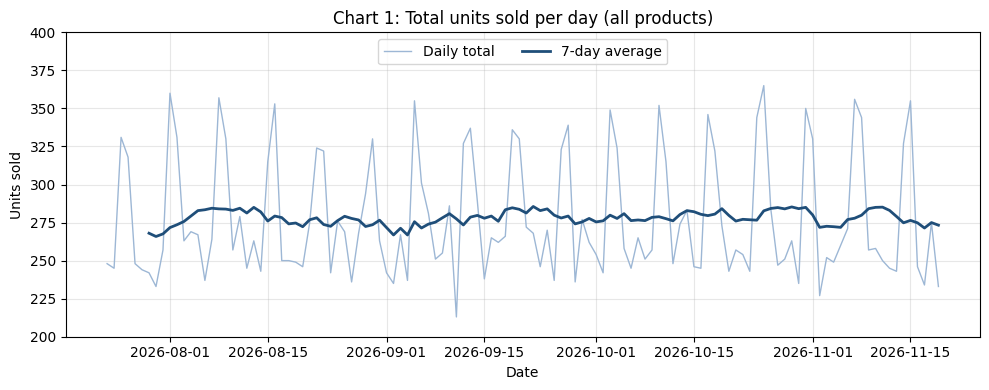

In [14]:
risk_colors = {"Critical": "#B3261E", "High": "#E8710A", "Medium": "#E0B000", "Low": "#2E7D32"}

# Chart 1: total units sold per day, with 7-day moving average
daily_total = sales.sum(axis=1)
moving_avg = daily_total.rolling(7).mean()

plt.figure(figsize=(10, 4))
plt.plot(daily_total.index, daily_total.values, color="#9DB7D5", linewidth=1, label="Daily total")
plt.plot(moving_avg.index, moving_avg.values, color="#1F4E79", linewidth=2, label="7-day average")
plt.title("Chart 1: Total units sold per day (all products)")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.ylim(200, 400)                      # extra space at the top for the legend
plt.legend(loc="upper center", ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

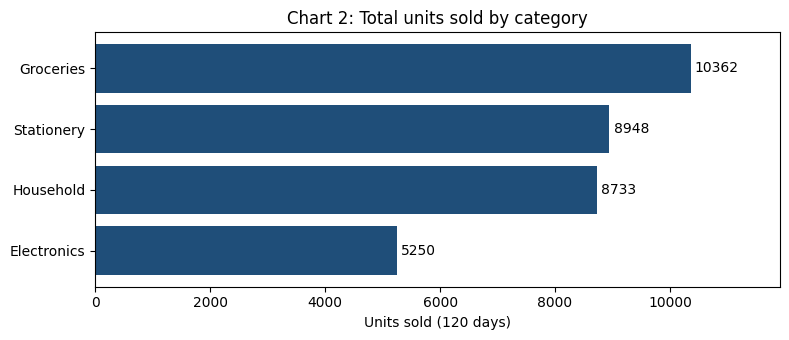

In [15]:
# Chart 2: units sold in each category
cat_units = inventory.groupby("category")["total_units_sold"].sum().sort_values()

plt.figure(figsize=(8, 3.5))
bars = plt.barh(cat_units.index, cat_units.values, color="#1F4E79")
plt.bar_label(bars, fmt="%d", padding=3)
plt.title("Chart 2: Total units sold by category")
plt.xlabel("Units sold (120 days)")
plt.xlim(0, cat_units.max() * 1.15)
plt.tight_layout()
plt.show()

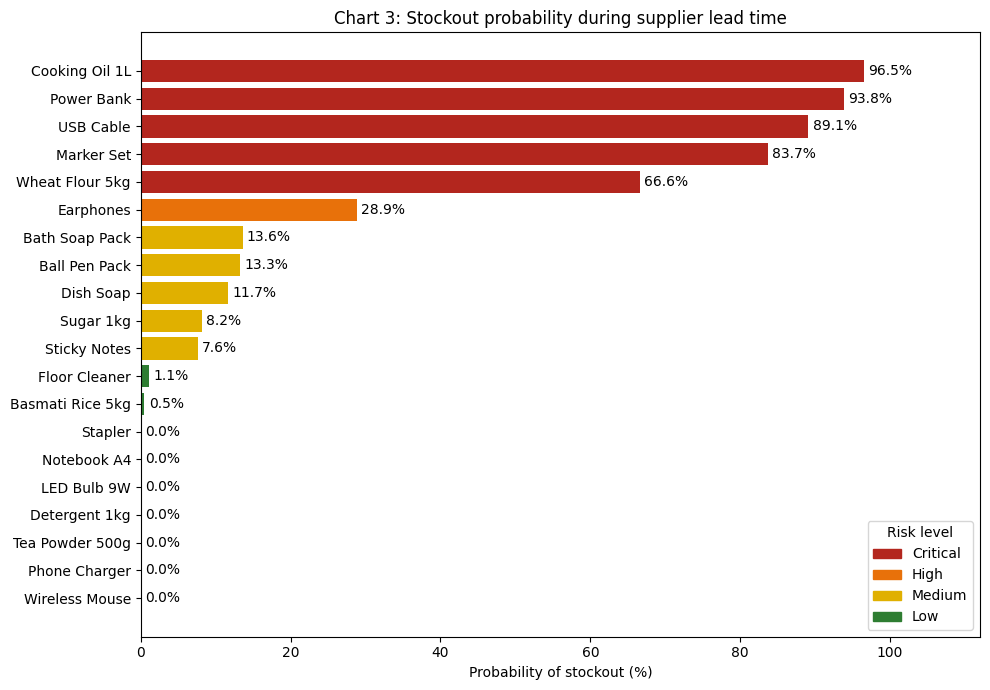

In [16]:
# Chart 3: stockout probability of every product (colour = risk level)
plot_df = inventory.sort_values("stockout_prob_pct")
colors = [risk_colors[r] for r in plot_df["risk_level"]]

plt.figure(figsize=(10, 7))
bars = plt.barh(plot_df["product_name"], plot_df["stockout_prob_pct"], color=colors)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Chart 3: Stockout probability during supplier lead time")
plt.xlabel("Probability of stockout (%)")
plt.xlim(0, 112)

# legend for the colours
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=risk_colors[r], label=r) for r in risk_order], title="Risk level", loc="lower right")
plt.tight_layout()
plt.show()

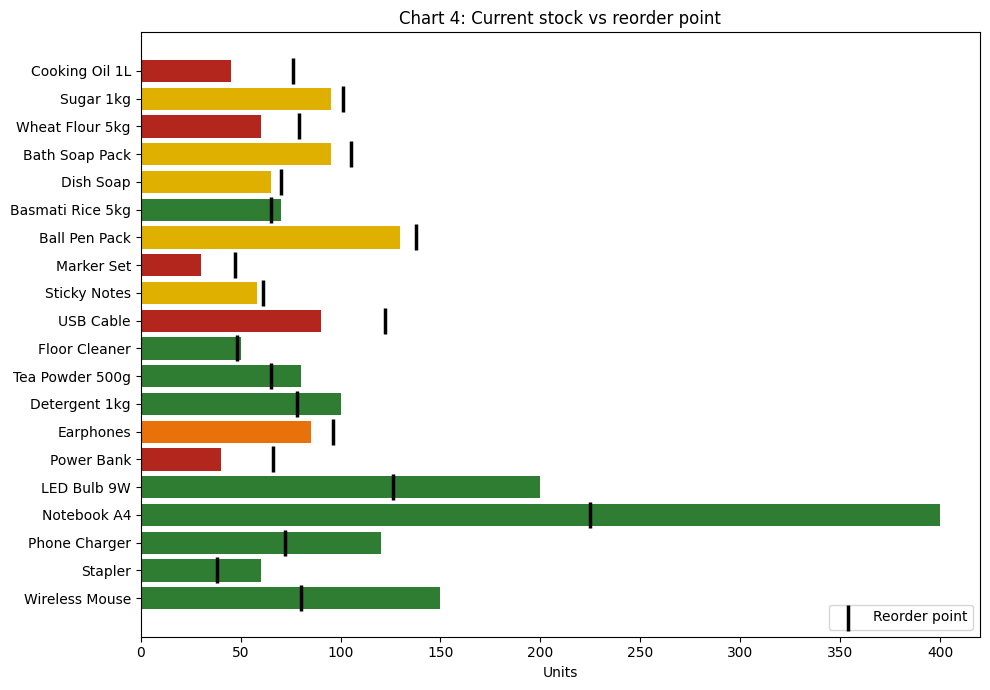

In [17]:
# Chart 4: current stock (bar) versus reorder point (black line mark)
plot_df = inventory.sort_values("days_of_stock_left", ascending=False)
colors = [risk_colors[r] for r in plot_df["risk_level"]]

plt.figure(figsize=(10, 7))
plt.barh(plot_df["product_name"], plot_df["current_stock"], color=colors)
plt.scatter(plot_df["reorder_point"], plot_df["product_name"], marker="|", s=350,
            color="black", linewidths=2.5, label="Reorder point", zorder=3)
plt.title("Chart 4: Current stock vs reorder point")
plt.xlabel("Units")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

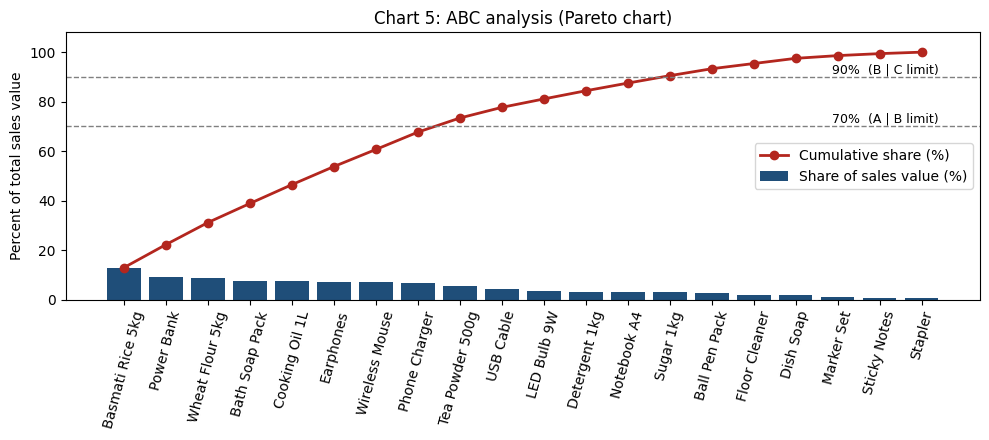

In [18]:
# Chart 5: ABC (Pareto) chart - bars = share of each product, line = running total
plt.figure(figsize=(10, 4.5))
plt.bar(abc["product_name"], abc["share_pct"], color="#1F4E79", label="Share of sales value (%)")
plt.plot(abc["product_name"], abc["cumulative_pct"], color="#B3261E", marker="o", linewidth=2,
         label="Cumulative share (%)")

plt.axhline(70, color="grey", linestyle="--", linewidth=1)    # A / B boundary
plt.axhline(90, color="grey", linestyle="--", linewidth=1)    # B / C boundary
plt.text(19.4, 71.5, "70%  (A | B limit)", ha="right", fontsize=9)
plt.text(19.4, 91.5, "90%  (B | C limit)", ha="right", fontsize=9)

plt.xticks(rotation=75)
plt.ylabel("Percent of total sales value")
plt.ylim(0, 108)
plt.title("Chart 5: ABC analysis (Pareto chart)")
plt.legend(loc="center right")
plt.tight_layout()
plt.show()

## Step 13: Final findings

In [19]:
critical = inventory[inventory["risk_level"] == "Critical"]["product_name"].tolist()
high = inventory[inventory["risk_level"] == "High"]["product_name"].tolist()
shortest = inventory.sort_values("days_of_stock_left").iloc[0]
top_cat = inventory.groupby("category")["total_units_sold"].sum().idxmax()
risky_cat = inventory.groupby("category")["stockout_prob_pct"].mean().idxmax()

print("=" * 60)
print("WAREHOUSE INVENTORY & STOCKOUT RISK - SUMMARY")
print("=" * 60)
print("Products analysed                 :", len(inventory))
print("Total stock value (Rs)            :", int(inventory["stock_value"].sum()))
print("Products at/below reorder point   :", int((inventory["reorder_now"] == "Yes").sum()))
print("Critical risk products            :", len(critical), "->", ", ".join(critical))
print("High risk products                :", len(high), "->", ", ".join(high))
print("Lowest stock cover                :", shortest["product_name"], "-", shortest["days_of_stock_left"], "days")
print("Best-selling category (units)     :", top_cat)
print("Category with highest avg risk    :", risky_cat)
print("Class A products                  :", int((inventory["abc_class"] == "A").sum()))
print("Budget needed for reorders (Rs)   :", int(inventory["order_cost"].sum()))

WAREHOUSE INVENTORY & STOCKOUT RISK - SUMMARY
Products analysed                 : 20
Total stock value (Rs)            : 337455
Products at/below reorder point   : 11
Critical risk products            : 5 -> USB Cable, Power Bank, Cooking Oil 1L, Wheat Flour 5kg, Marker Set
High risk products                : 1 -> Earphones
Lowest stock cover                : Cooking Oil 1L - 2.3 days
Best-selling category (units)     : Groceries
Category with highest avg risk    : Electronics
Class A products                  : 8
Budget needed for reorders (Rs)   : 364025


## Step 14: Save the result as a CSV file
The final table can be opened in Excel. In Google Colab this cell also downloads the file to your computer.

In [20]:
final_report = inventory.sort_values(["risk_level", "stockout_prob_pct"], ascending=[True, False])
final_report.to_csv("inventory_risk_report.csv", index=False)
print("Saved: inventory_risk_report.csv  (rows:", len(final_report), ")")

try:
    from google.colab import files
    files.download("inventory_risk_report.csv")   # works only inside Google Colab
except ImportError:
    print("Not running in Colab - the file is saved in the current folder.")

Saved: inventory_risk_report.csv  (rows: 20 )


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- We built a complete **inventory and stockout risk analysis** using only **Python, NumPy and pandas** (plus matplotlib charts).
- NumPy was used for random data, broadcasting, `where`, `ceil`, `sqrt` and Monte Carlo simulation.
- pandas was used for DataFrames, `merge`, `groupby`, `crosstab`, `cumsum` and sorting.
- The risk list tells the manager **which products to order first**, and the ABC class tells **which products matter most**.
